In [1]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
import matplotlib.pyplot as plt 
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
import scipy.stats as ss
import time

In [2]:
MIN_X, MAX_X = -1, 1
P_NATURE = np.random.random(size=1) * 2 - 1
P_NATURE[0] = 1

def nature(x: float, params: list[int] = P_NATURE):
    return np.poly1d(np.poly(params))(x)

def measure(x: float, error: float = 0):
    return nature(x) + error * np.random.normal(0, 1)


In [3]:
def plot(regressor: GaussianProcessRegressor, rng: tuple[float] = (MIN_X, MAX_X)):
    x = np.linspace(rng[0], rng[1], 1000)
    y = nature(x)
    plt.plot(x, y, label='nature', color='black', linestyle="dashed")
    plt.ylim([min(y) * 1.1, max(y) * 1.1])
    
    try: 
        x_train = regressor.X_train_
        if regressor.X_train_ is not None:
            print(regressor.X_train_)
            x_train = regressor.X_train_
            y_train = regressor.y_train_
            plt.scatter(x_train, y_train, label='measure', color='red', marker='x')
    except AttributeError:
        pass

    y_mean, y_std = regressor.predict(x.reshape(-1, 1), return_std=True)
    plt.plot(x, y_mean, label='mean', color='blue')
    plt.fill_between(x, y1=y_mean + y_std, y2=y_mean - y_std, label='std', color='blue', alpha=0.1)

    plt.ylim([min((min(y), min(y_std))) * 1.1, max(max(y), max(y_std)) * 1.1])
    plt.title('Gaussian Process Regression')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()e
    plt.grid()
    plt.show()

def update_data(regressor: GaussianProcessRegressor, x: float, y: float):
    try:
        current_x = regressor.X_train_
    except AttributeError:
        current_x = None
    if current_x is not None:
        
        print(current_x.shape, x.shape)
        x = np.concatenate((current_x, x.reshape(-1, 1)))
    else:
        x = x.reshape(-1, 1)

    y = measure(x)
    if len(x) > 0:
        regressor.fit(x, y)
    return regressor

def select_x() -> tuple[float, float]:
    try:
        x = float(input("x: "))
        if x < MIN_X or x > MAX_X:
            print(f"Please enter a number between {MIN_X} and {MAX_X}.")
            return None
        print(f"{x=}, {type(x)=}")
        y = measure(x, error=0.5)
    except ValueError:
        print(f"{x=}, {type(x)=}")
        if list(x) == []:
            return None
        print("Invalid input. Please enter a number.")
        return None
    return x, y

def highest_std(regressor) -> tuple[float, float]:
    time.sleep(1)
    x = np.linspace(MIN_X, MAX_X, 1000)
    y_mean, y_std = regressor.predict(x.reshape(-1, 1), return_std=True)
    max_std_index = np.argmax(y_std)
    return x[max_std_index], y_std[max_std_index]

rbf = 1 * RBF(length_scale=0.3)
regressor = GaussianProcessRegressor(kernel=rbf, random_state=0, alpha=0.1)

n_init = 0
x = np.random.uniform(MIN_X, MAX_X, n_init)
y = measure(x)

if len(x) > 0:
    regressor.fit(x.reshape(-1, 1), y)

plot(regressor)

while True:

        x, y = highest_std(regressor)
        regressor = update_data(regressor, np.array([x]), np.array([y]))
        clear_output(wait=True)
        plot(regressor)

SyntaxError: invalid syntax (4041350127.py, line 25)

In [4]:

x0 = 1
y0 = 2
sigma = 0.1

m = 1
b = 1

correlations = []
y0s = ss.norm(loc=m*x0 + b, scale=sigma).rvs(1000)
x1s = np.linspace(0, 10, 100)
for x1 in x1s:
    ys = ss.norm(loc=m*x + b, scale=sigma).rvs(1000)
    correlations.append(ss.pearsonr(ys, y0s)[0])

plt.plot(x1s, correlations)
plt.title('Correlation between y0 and y1')
plt.xlabel('x1')
plt.ylabel('Correlation')
plt.grid()
plt.show()


NameError: name 'x' is not defined

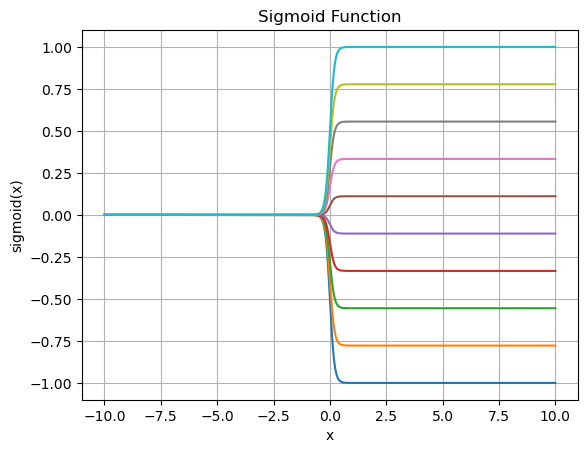

In [5]:
def sigmoid(x, a, b, c):
    return c * 1 / (1 + np.exp(-(x - a) / b))

x = np.linspace(-10, 10, 1000)
a = 0
b = 0.1
c = -1
[plt.plot(x, sigmoid(x, a, b, c)) for c in np.linspace(-1, 1, 10)]
plt.title('Sigmoid Function')
plt.xlabel('x')
plt.ylabel('sigmoid(x)')
plt.grid()
plt.show()